# Módulo 6 — Decomposição de séries temporais

## Seção 1 — Decomposição clássica aditiva e multiplicativa: teoria, estimação e diagnóstico

**Estado editorial:** material para estudo e revisão científica. **Pré-requisitos:** processo estocástico; função média e variância; tendência, sazonalidade e médias móveis (Módulo 2); diferença entre trajetória e modelo; transformações logarítmicas e Box–Cox (Módulo 5). **Ambiente:** Python 3, NumPy, Pandas, Matplotlib e Statsmodels.

**Rastreabilidade:** a formulação aditiva, a finalidade do ajuste sazonal e a cautela com a estimação conjunta baseiam-se em Morettin e Toloi, *Análise de Séries Temporais: Modelos lineares univariados*, v. 1, cap. 3, §3.1, p. impressa 51 (p. 70 do PDF), eqs. (3.1)–(3.2), conferidas visualmente; o uso de filtros de médias móveis é discutido em §3.2.2, pp. 55–56 (PDF pp. 74–75). O catálogo `mapeamento-conteudos-series-temporais.md`, Bloco A (*Aula 2 — Parte I* e *Modelos de Decomposição*) orienta a sequência. **Complementação didática original:** modelo multiplicativo detalhado, derivação do filtro 2×4, cálculos numéricos, comparações entre escalas, implementação, figuras, exercícios e advertências de validação. Não atribuímos esses desenvolvimentos a páginas não verificadas.

### Objetivos de aprendizagem

Ao terminar, você deverá (1) definir componentes não observados; (2) distinguir modelo aditivo e multiplicativo com suas hipóteses; (3) executar manualmente o filtro 2×4; (4) obter índices sazonais e resíduos; (5) compreender por que a decomposição é uma estimativa dependente do método; (6) reproduzir uma decomposição no Statsmodels; e (7) reconhecer as limitações para previsão.

### 1. Problema: o valor observado contém componentes diferentes

Uma série trimestral pode crescer lentamente e, simultaneamente, repetir picos nos mesmos trimestres. Queremos separar **tendência** (movimento de baixa frequência), **sazonalidade** (padrão associado ao calendário) e **irregularidade** (o que o procedimento não explica). Decompor não significa recuperar automaticamente componentes verdadeiros: em dados reais, só observamos a soma ou o produto deles e precisamos escolher restrições para estimá-los.

Na notação usada ao longo do livro, a decomposição **aditiva** é

$$
\boxed{Z_t=T_t+S_t+a_t.}
$$

- $Z_t$: observação no instante $t$;
- $T_t$: nível ou tendência, frequentemente suave;
- $S_t$: efeito sazonal, com período $s$;
- $a_t$: componente irregular; sua natureza de ruído branco **não está garantida** pelo ato de decompor.

Uma decomposição exige hipóteses de identificação. Se não impusermos restrições, a igualdade não determina componentes únicos: para qualquer função $c_t$, poderíamos substituir $T_t$ por $T_t+c_t$ e $S_t$ por $S_t-c_t$ sem mudar $Z_t$. Por isso precisamos de regras como suavidade da tendência, repetição sazonal e normalização dos índices.

### 2. Aditiva versus multiplicativa

No modelo **aditivo**, a amplitude sazonal é expressa nas mesmas unidades de $Z_t$:

$$
Z_t=T_t+S_t+a_t,\quad S_{t+s}=S_t,\quad\sum_{j=1}^s S_j=0.
$$

A restrição de soma zero fixa a separação entre nível e efeitos sazonais. Em um modelo multiplicativo clássico, para valores estritamente positivos:

$$
\boxed{Z_t=T_t\,S_t\,I_t,\qquad T_t>0,\;S_t>0,\;I_t>0.}
$$

Aqui $S_t$ representa um **fator relativo**: $S_t=1{,}20$ indica nível sazonal 20% acima da tendência, na ausência de irregularidade multiplicativa. Uma normalização comum é $s^{-1}\sum_{j=1}^s S_j=1$. Outra convenção é média **geométrica** igual a 1; são diferentes e precisam ser declaradas. Se a amplitude oscila proporcionalmente ao nível, a forma multiplicativa pode descrever melhor o fenômeno; essa impressão visual, por si só, não justifica a especificação.

A transformação logarítmica oferece uma ponte exata quando todos os fatores são positivos:

$$
\log Z_t=\log T_t+\log S_t+\log I_t.
$$

**Cuidado:** decompor $\log Z_t$ e reverter componentes não é idêntico, em amostras finitas, a aplicar um procedimento clássico multiplicativo diretamente a $Z_t$. Filtros lineares e exponenciação não comutam: $\exp(\overline{\log Z})$ geralmente difere de $\overline Z$.

| Critério | Aditivo | Multiplicativo |
|---|---|---|
| Equação | $Z=T+S+a$ | $Z=T\times S\times I$ |
| Unidade sazonal | Unidade da série | Fator relativo |
| Normalização usual | Média sazonal zero | Média aritmética sazonal um |
| Remoção sazonal | $Z_t-\widehat S_t$ | $Z_t/\widehat S_t$ |
| Restrição de sinal | Não exige positividade | Fatores e observações positivos |

### 3. Exemplo resolvido de interpretação de componentes

Considere tendência $T_t=100$, efeito aditivo do primeiro trimestre $S_t=-10$ e irregularidade $a_t=3$. A observação seria $Z_t=100-10+3=93$. O ajuste sazonal aditivo resultaria $Z_t^{SA}=93-(-10)=103$; a **tendência** continua sendo 100 e o irregular é 3. Portanto, série dessazonalizada **não** significa série sem ruído.

No modelo multiplicativo, com $T_t=100$, índice sazonal $S_t=0{,}9$ e irregular $I_t=1{,}03$, teríamos $Z_t=100(0{,}9)(1{,}03)=92{,}7$ e $Z_t^{SA}=92{,}7/0{,}9=103$. São mecanismos distintos que, neste caso, produzem dessazonalizados iguais. A igualdade numérica não autoriza confundir os parâmetros $a_t=3$ e $I_t=1{,}03$.

### 4. Decomposição clássica por médias móveis — por que esta ordem?

No caso de dados trimestrais com $s=4$, é comum seguir o procedimento: **(i)** estimar tendência com médias móveis centradas; **(ii)** retirar a tendência por subtração/divisão; **(iii)** calcular médias por posição no ciclo; **(iv)** normalizar efeitos; **(v)** obter resíduos. Isso explora a repetição sazonal para estimar uma função que não observamos diretamente.

Para período ímpar $s=2m+1$, uma média de $s$ termos pode ser centrada em uma observação:

$$
\widehat T_t=\frac{1}{s}\sum_{j=-m}^m Z_{t+j}.
$$

Para período **par**, por exemplo $s=4$, a média de quatro termos tem centro entre instantes. Duas médias sucessivas de quatro termos, depois promediadas, produzem o filtro **2×4**:

$$
\boxed{\widehat T_t=\frac18 Z_{t-2}+\frac14 Z_{t-1}+\frac14 Z_t+\frac14 Z_{t+1}+\frac18 Z_{t+2}.}
$$

A soma dos pesos é 1. O filtro é simétrico, de modo que $\sum_jj w_j=0$; por isso preserva uma tendência exatamente linear nos pontos internos. A periodicidade sazonal de período 4 e soma zero garante que a combinação ponderada de quatro estações tenha efeito sazonal total nulo. Isso é uma identidade algébrica, **não** uma prova de que a tendência foi recuperada em presença de ruído.

### 5. Exemplo manual: filtro 2×4, estimativa sazonal e resíduo

Considere oito observações fictícias trimestrais:

$$
(z_1,\ldots,z_8)=(18,22,28,24,22,26,32,28).
$$

Na posição $t=3$, a média centrada 2×4 é

$$
\begin{aligned}
\widehat T_3&=\frac18(18)+\frac14(22)+\frac14(28)+\frac14(24)+\frac18(22)\\
&=2{,}25+5{,}5+7+6+2{,}75=23{,}5.
\end{aligned}
$$

Na posição $t=4$:

$$
\widehat T_4=\frac18(22)+\frac14(28)+\frac14(24)+\frac14(22)+\frac18(26)=24{,}5.
$$

Analogamente, $\widehat T_5=25{,}5$ e $\widehat T_6=26{,}5$; os instantes 1, 2, 7 e 8 não possuem filtro completo. Os valores sem tendência disponíveis são, respectivamente,

$$
(z_3-\widehat T_3,z_4-\widehat T_4,z_5-\widehat T_5,z_6-\widehat T_6)
=(4{,}5,-0{,}5,-3{,}5,-0{,}5).
$$

Como temos **apenas um resíduo preliminar por trimestre**, normalizar sua média (a média dos quatro valores é zero) devolve índices sazonais $(\widehat S_1,\widehat S_2,\widehat S_3,\widehat S_4)=(-3{,}5,-0{,}5,4{,}5,-0{,}5)$. A identificação de trimestre é $t=1,5,9,\ldots$ para T1; $t=2,6,10,\ldots$ para T2; etc. Neste exercício pequeno, os índices são instáveis e a decomposição não oferece evidência empírica suficiente sobre sazonalidade futura.

Por exemplo, para $t=3$, $\widehat a_3=28-23{,}5-4{,}5=0$; para uma amostra geral, os resíduos não serão zero. Aqui a construção linear e o tamanho mínimo do exemplo explicam esse resultado. É crucial **não** usar esse exemplo para concluir que a decomposição fornece inovações independentes.

### 6. Formalização algorítmica das etapas

Para cada posição sazonal $j\in\{1,\ldots,s\}$, denote por $I_j$ os instantes internos para os quais $\widehat T_t$ existe e o instante pertence à estação $j$.

No modelo aditivo:

$$
R_t=Z_t-\widehat T_t,\qquad
\widetilde S_j=\frac1{|I_j|}\sum_{t\in I_j}R_t,
$$

$$
\widehat S_j=\widetilde S_j-\frac1s\sum_{r=1}^s\widetilde S_r,
\qquad \widehat a_t=Z_t-\widehat T_t-\widehat S_{j(t)}.
$$

No multiplicativo, com $\widehat T_t>0$:

$$
R_t=\frac{Z_t}{\widehat T_t},\qquad
\widetilde S_j=\frac1{|I_j|}\sum_{t\in I_j} R_t,
$$

$$
\widehat S_j=\frac{\widetilde S_j}{s^{-1}\sum_{r=1}^{s}\widetilde S_r},
\qquad\widehat I_t=\frac{Z_t}{\widehat T_t\widehat S_{j(t)}}.
$$

O uso de médias por estação exige observações internas em **todas** as posições sazonais; caso alguma estação não tenha observação válida, o índice correspondente não estará identificado por esse procedimento. Outros softwares podem utilizar variantes, extrapolação das bordas ou definições de filtro diferentes. Registre as convenções.

### 7. Implementação em Python: decomposição e diagnóstico

Vamos simular 48 trimestres com tendência linear, quatro efeitos de soma zero e ruído normal independente. Para evitar confundir método com modelo, compararemos o resultado do algoritmo a componentes verdadeiros **conhecidos apenas porque simulamos os dados**. `seasonal_decompose` utiliza uma decomposição por filtro de médias móveis e estima índices sazonais; `period=4` informa a duração do ciclo; `extrapolate_trend=0` mantém bordas ausentes em vez de inventar observações.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

rng = np.random.default_rng(20261119)
n, s = 48, 4
t = np.arange(n)
T = 25 + 0.35 * t
padrao = np.array([-3., 1., 4., -2.])
S = padrao[t % s]
a = rng.normal(0, 0.8, size=n)
z = T + S + a
serie = pd.Series(z, index=pd.period_range('2015Q1', periods=n, freq='Q'))

decomp = seasonal_decompose(serie, model='additive', period=s,
                            extrapolate_trend=0)
assert np.isnan(decomp.trend.iloc[:2]).all()
assert np.isnan(decomp.trend.iloc[-2:]).all()
validos = ~np.isnan(decomp.resid.to_numpy())
assert np.allclose(z[validos],
    (decomp.trend + decomp.seasonal + decomp.resid).to_numpy()[validos])

fig, axs = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
axs[0].plot(t, z, label='Observações')
axs[0].plot(t, T, '--', label='Tendência verdadeira')
axs[1].plot(t, decomp.trend.to_numpy(), label='Tendência estimada')
axs[2].plot(t, decomp.seasonal.to_numpy(), label='Sazonalidade estimada')
axs[3].plot(t, decomp.resid.to_numpy(), label='Resíduo da decomposição')
for ax in axs:
    ax.legend(loc='upper left')
    ax.grid(alpha=0.2)
axs[-1].set_xlabel('Trimestre (índice)')
plt.tight_layout()
plt.show()

print('Índices sazonais estimados por trimestre:',
      np.round(decomp.seasonal.to_numpy()[:4], 3))

**Leitura do código:** `period_range` cria um calendário trimestral regular; `pd.Series` associa valores a esse calendário; `seasonal_decompose` fornece objetos `trend`, `seasonal` e `resid`; `np.isnan` identifica a tendência ausente nas bordas; a igualdade verificada pelo `assert` é a **identidade de reconstrução** da decomposição, não comprovação de que os componentes estimados sejam os verdadeiros.

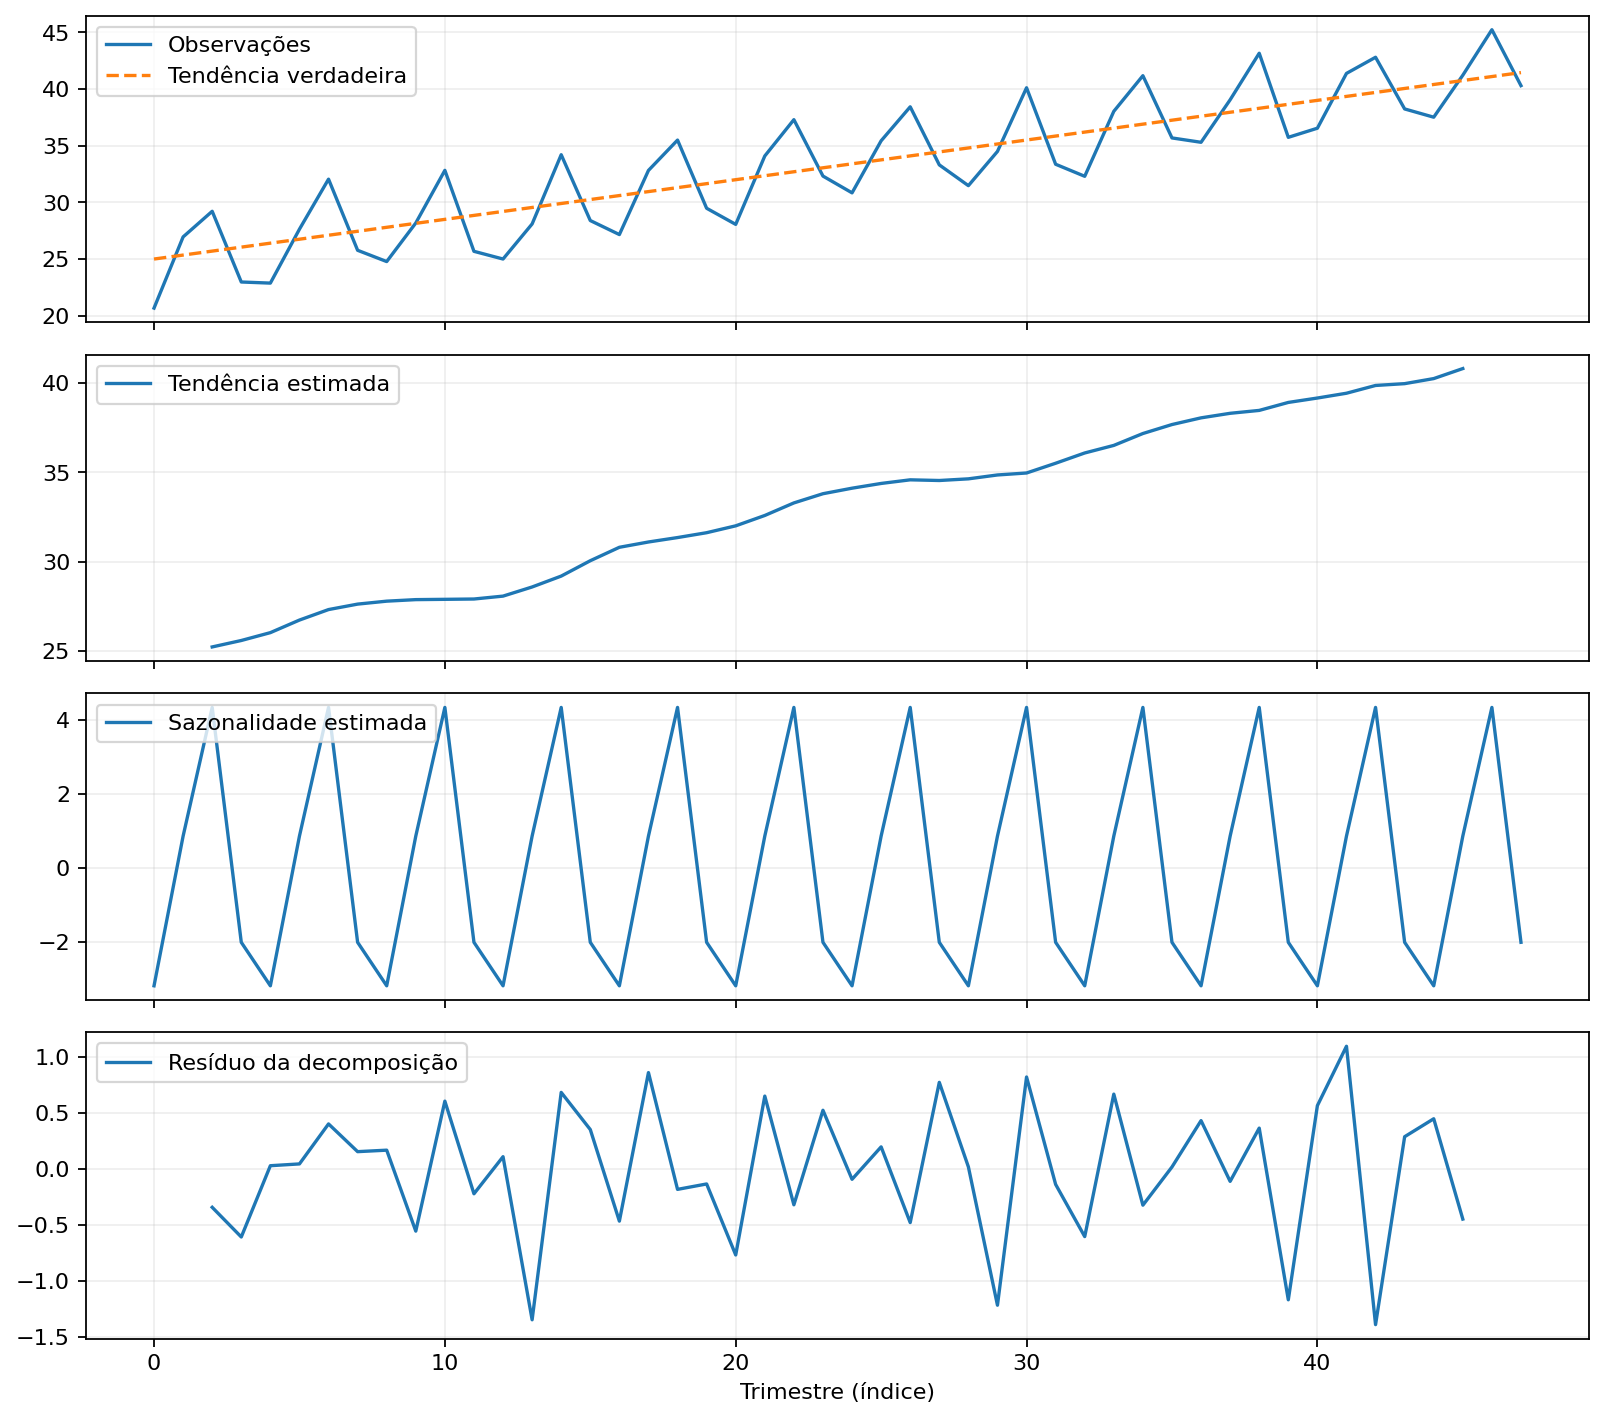

*Figura 6.1 — Série sintética e estimativas clássicas: a tendência suavizada perde dois pontos em cada extremidade; sazonalidade permanece periódica e o resíduo é o que sobra. A tendência verdadeira aparece apenas no código de simulação.*

### 8. Multiplicativo na prática: escala e restrições

In [ ]:
rng = np.random.default_rng(20261120)
n, s = 48, 4
t = np.arange(n)
Tmul = 30 * np.exp(0.015 * t)
S_mul = np.array([0.82, 1.02, 1.26, 0.90])[t % s]  # média = 1
I_mul = np.exp(rng.normal(-0.04**2 / 2, 0.04, size=n))
z_mul = Tmul * S_mul * I_mul
multip = seasonal_decompose(z_mul, model='multiplicative', period=s,
                             extrapolate_trend=0)
validos = np.isfinite(multip.resid)
assert np.allclose(z_mul[validos],
   (multip.trend * multip.seasonal * multip.resid)[validos])
print('Média dos quatro índices estimados:', np.mean(multip.seasonal[:4]))

A série deve permanecer positiva para interpretar fatores e executar o método multiplicativo. Aqui a tendência **exponencial** não é preservada exatamente pelo filtro 2×4 como seria uma reta aditiva; portanto, nem mesmo uma simulação com fatores periódicos garante recuperação exata dos componentes verdadeiros.

### 9. Limitações e avaliação científica

**Identificação:** tendência, sazonalidade e irregularidade são componentes estimados sob regras; outras regras produzem outras decomposições. **Bordas:** filtros centrados não dispõem de vizinhança completa no início e no fim. **Sazonalidade fixa:** o método clássico trata o ciclo como repetitivo; alterações gradativas dos efeitos sazonais não são acompanhadas automaticamente. **Dependência residual:** subtrair as estimativas não implica ruído branco; ACF/PACF e outros diagnósticos continuam relevantes. **Mudanças estruturais:** choques e transições podem ser distribuídos inadequadamente entre tendência e resíduo. **Dados ausentes:** o método exige atenção à regularidade temporal e a valores faltantes; não os substitua automaticamente por zero. **Previsão:** um filtro centrado que usa $Z_{t+1}$ não é uma estimativa disponível no instante $t$; executar a decomposição na série inteira antes de separar treino e teste vaza informação futura.

### 10. Exercícios graduais

1. **Conceitual:** explique por que $Z_t-\widehat S_t$ não é, em geral, igual a $\widehat T_t$.
2. **Numérico:** calcule $\widehat T_5$ no exemplo manual usando o filtro 2×4 e confira $25{,}5$.
3. **Demonstração:** prove que os pesos $(1/8,1/4,1/4,1/4,1/8)$ anulam qualquer sazonalidade trimestral fixa com soma zero.
4. **Modelagem:** para duas séries de mesmo período, uma com amplitude absoluta constante e outra com amplitude proporcional ao nível, discuta qual modelo inicial faz mais sentido e quais hipóteses adicionais precisam ser examinadas.
5. **Python:** escreva pseudocódigo do filtro 2×4 e implemente um cálculo manual que produza `NaN` nas extremidades. Compare-o com `decomp.trend`.
6. **Pesquisa:** se o objetivo é previsão de energia trimestral, descreva um procedimento cronológico para estimar índices sazonais sem usar dados posteriores à origem de previsão.

**Pistas:** no exercício 3, as duas extremidades somadas têm peso total $1/4$, completando quatro posições de peso $1/4$. No exercício 5, o primeiro índice calculável é $t=3$ em notação iniciada em 1.

### 11. Síntese e referências

A decomposição clássica depende de filtros, normalização e uma hipótese de sazonalidade repetitiva. Uma identidade $Z=\widehat T+\widehat S+\widehat a$ não comprova a qualidade estatística de cada estimativa. O passo seguinte é compreender **regressão local LOESS**, que substitui uma tendência global por ajustes ponderados em vizinhanças e prepara o STL.

**Referências:** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de Séries Temporais: Modelos lineares univariados*, v. 1, 3ª ed., cap. 3, §3.1, p. 51, eqs. (3.1)–(3.2); §3.2.2, pp. 55–56, eqs. (3.14)–(3.15), páginas verificadas visualmente. **Mapa de videoaulas:** `mapeamento-conteudos-series-temporais.md`, Bloco A. **Complementações originais:** tratamento multiplicativo, operações algébricas, exemplos, simulações e exercícios. A referência computacional para `seasonal_decompose` é a biblioteca Statsmodels; detalhes de implementação podem depender da versão instalada.